# East Siberia 2020: tundra vs. taiga detections

VIFDAHL run `eastsiberia_2020`: SNPP, local solar dates 2020-06-01 to 2020-09-30. Each AOI is
the union of the 2020 large-fire perimeters (TaLuCi dataset) in one ecoregion. The biome
(tundra or taiga) comes from the AOI file's `BIOME_1` column.

Counts reflect the AOI areas: the taiga AOI covers ~59,000 km², the two tundra AOIs together
~3,800 km². Histograms are therefore normalized.

In [1]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

from vifdahl.analysis import load_points, plot_date_scatter, plot_histograms, plot_tb_scatter

GPKG_ROOT = Path("../output/eastsiberia_2020/gpkg")
AOI_FILE = Path("../data/input/2020_eastsiberia/eastsiberia_large_fires_2020_merged.geojson")
FIG_DIR = Path("../output/eastsiberia_2020/figures")
FIG_DIR.mkdir(exist_ok=True)

In [2]:
aois = gpd.read_file(AOI_FILE)
biome = dict(zip(aois["EcoName"].str.replace(" ", "_"), aois["BIOME_1"]))
biome

{'Northeast_Siberian_coastal_tundra': 'tundra',
 'Bering_tundra': 'tundra',
 'Northeast_Siberian_taiga': 'taiga'}

In [3]:
points = load_points(GPKG_ROOT)
points["biome"] = points["aoi_id"].map(biome)
assert points["biome"].notna().all()
print(f"{len(points):,} detections; platforms: {', '.join(points['Platform'].unique())}")

398,772 detections; platforms: NPP


## Detection counts

In [4]:
pd.crosstab([points["biome"], points["aoi_id"]], points["Type"], margins=True)

Type                                          A       H       L     All
biome  aoi_id                                                          
taiga  Northeast_Siberian_taiga           23325  229183  128944  381452
tundra Bering_tundra                        853    6533    2700   10086
       Northeast_Siberian_coastal_tundra    497    5553    1184    7234
All                                       24675  241269  132828  398772

In [5]:
pd.crosstab([points["biome"], points["sun"]], points["Type"])

Type                 A       H      L
biome  sun                           
taiga  sun down    417   21952  60750
       sun up    22908  207231  68194
tundra sun down     77    1687   1383
       sun up     1273   10399   2501

In [6]:
points.loc[points["Type"] != "A"].groupby(["biome", "sun", "Type"])[["TB4", "TB5", "ndiff"]] \
    .median().round(3)

TB4      TB5  ndiff
biome  sun      Type                         
taiga  sun down H     321.775  283.501  0.063
                L     297.802  280.877  0.031
       sun up   H     338.572  294.943  0.066
                L     323.904  299.383  0.042
tundra sun down H     322.003  277.254  0.075
                L     296.099  277.315  0.036
       sun up   H     339.479  294.023  0.070
                L     322.868  299.117  0.042

## Histograms: tundra vs. taiga, H vs. L

**Sun up / sun down** is decided per pixel from the solar zenith angle (≤ 90° = sun up).
It is not the same as the `Period` column (local solar time 06–18 / 18–06) and not necessarily
the threshold set the algorithm applied. With `daynight = "scene"`, a whole granule is classified
with night thresholds unless every pixel is sunlit. North of ~66°N in June and July, the sun
never sets, so most "night" detections were made in daylight.

The day thresholds produce hard edges in the histograms: H and L require TB4 > 320 K and TB5 > 285 K.

A pixels (saturated or folded TB4) are counted in the tables but left out of all
brightness-temperature plots.

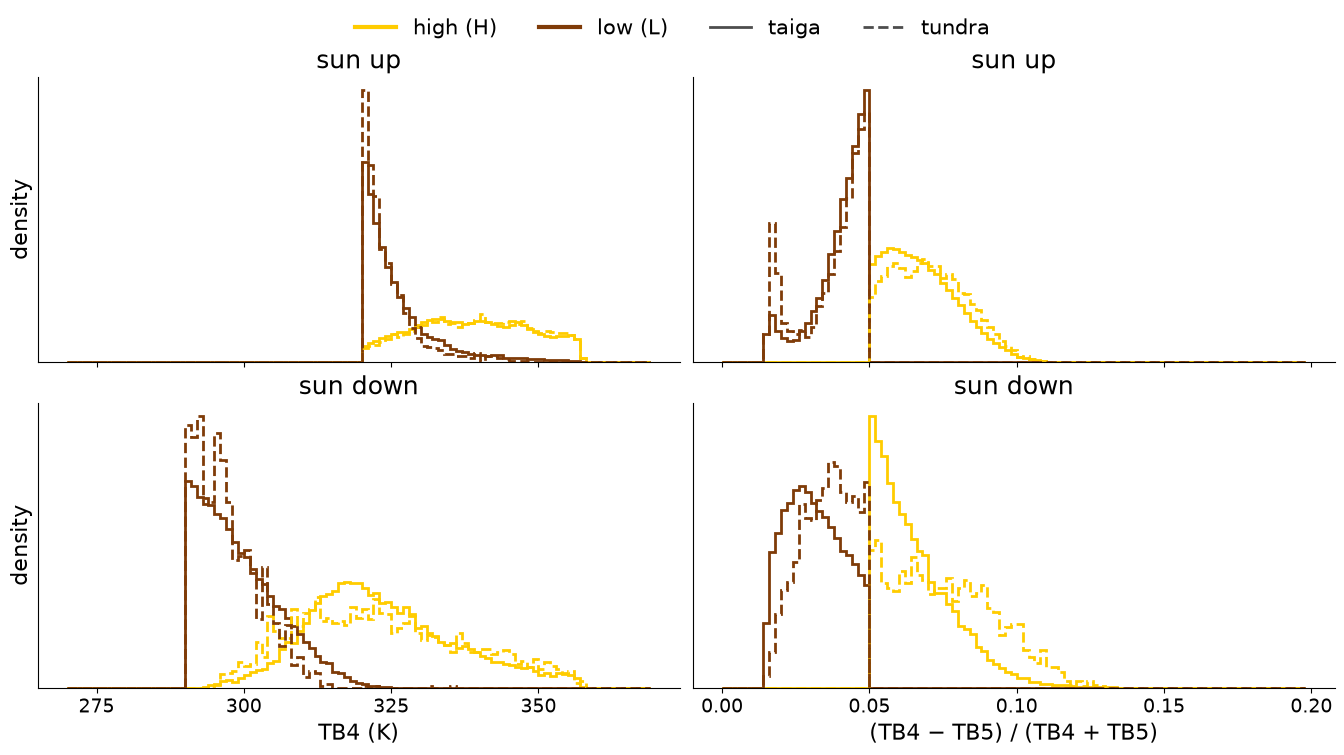

In [7]:
fig = plot_histograms(points, "biome")
fig.savefig(FIG_DIR / "hist_biome.png", dpi=150)

Same, with the two tundra ecoregions kept apart. The coastal tundra AOI has almost no sun-down detections (one L pixel); histogram series with fewer than 50 values are not drawn.

In [8]:
fig = plot_histograms(points, "aoi_id")
fig.savefig(FIG_DIR / "hist_ecoregion.png", dpi=150)

## TB4 vs. TB5, colored by local date

The taiga panels are subsampled to 200,000 points.

In [9]:
fig = plot_tb_scatter(points, "biome")
fig.savefig(FIG_DIR / "scatter_tb_date.png", dpi=150)

## TB4 over the season

Points are jittered by ±0.4 days within each local date.

In [10]:
fig = plot_date_scatter(points, "biome")
fig.savefig(FIG_DIR / "scatter_date_tb4.png", dpi=150)